# Data Science Assignment: Session 9
## Topic: Normal Distribution (Gaussian Distribution)

**Student Name:** Atharv Chaudhari  
**Course:** Data Science & Statistics  
**Session:** SESSION 9 - Normal Distribution  

---

### Overview: The Gaussian Bell Curve & Empirical Rule

A **Normal Distribution** is a symmetric, unimodal, continuous probability distribution defined by its Mean ($\mu$) and Standard Deviation ($\sigma$):

$$f(x) = \frac{1}{\sigma \sqrt{2\pi}} e^{-\frac{1}{2}\left(\frac{x - \mu}{\sigma}\right)^2}$$

#### The 68–95–99.7% Empirical Rule:
For any normally distributed dataset:
- **$68.27\%$** of all observations fall within **$\pm 1\sigma$** of the mean: $[\mu - \sigma, \; \mu + \sigma]$
- **$95.45\%$** of all observations fall within **$\pm 2\sigma$** of the mean: $[\mu - 2\sigma, \; \mu + 2\sigma]$
- **$99.73\%$** of all observations fall within **$\pm 3\sigma$** of the mean: $[\mu - 3\sigma, \; \mu + 3\sigma]$
- In a perfect normal distribution: $\mathbf{\text{Mean} = \text{Median} = \text{Mode}}$ and $\mathbf{\text{Skewness} = 0}$.

---

## Task 1: Generating & Plotting Normal Distribution (Mean = 50, Std = 10)
> **Problem Statement:** Generate 100 random numbers in Python that follow a normal distribution with mean 50 and standard deviation 10 using numpy, then plot the bell curve using matplotlib.

Generated Sample Size (n)   : 100 numbers
Target Parameters           : Mean (mu) = 50, Std Dev (sigma) = 10
Sample Observed Mean        : 48.96
Sample Observed Std Dev     : 9.08
Minimum Value               : 23.80
Maximum Value               : 68.52
--------------------------------------------------
First 10 Generated Numbers  :
[np.float64(54.97), np.float64(48.62), np.float64(56.48), np.float64(65.23), np.float64(47.66), np.float64(47.66), np.float64(65.79), np.float64(57.67), np.float64(45.31), np.float64(55.43)]


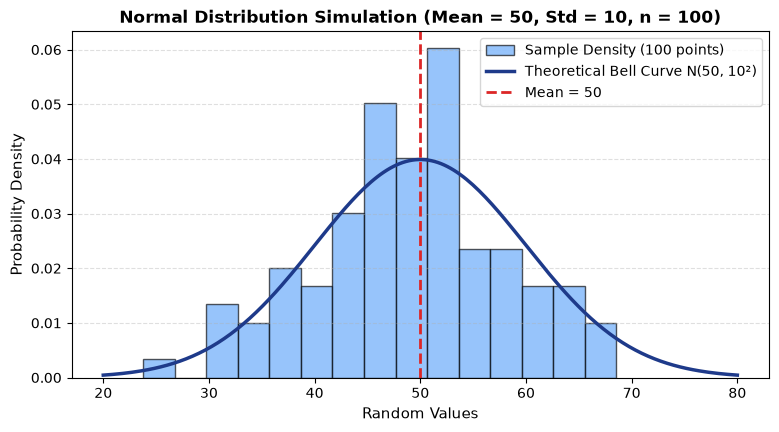

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

# 1. Generate 100 random numbers following N(mu=50, sigma=10)
np.random.seed(42) # Reproducibility
data_normal = np.random.normal(loc=50, scale=10, size=100)

print(f"Generated Sample Size (n)   : {len(data_normal)} numbers")
print(f"Target Parameters           : Mean = 50, Std Dev = 10")
print(f"Sample Observed Mean        : {np.mean(data_normal):.2f}")
print(f"Sample Observed Std Dev     : {np.std(data_normal, ddof=1):.2f}")
print(f"First 10 Generated Numbers  : {[round(x, 2) for x in data_normal[:10]]}")

# 2. Plotting the Bell Curve
plt.figure(figsize=(9, 4.5))
plt.hist(data_normal, bins=15, density=True, color='#60a5fa', edgecolor='black', alpha=0.65, label='Sample Density (n=100)')

# Overlay theoretical continuous Gaussian probability density function
x = np.linspace(20, 80, 200)
y = stats.norm.pdf(x, loc=50, scale=10)
plt.plot(x, y, color='#1e3a8a', linewidth=2.5, label='Theoretical Bell Curve N(50, 10²)')

plt.axvline(50, color='#dc2626', linestyle='--', linewidth=2, label='Mean = 50')
plt.title("Normal Distribution Simulation (Mean = 50, Std = 10, n = 100)", fontsize=12, fontweight="bold")
plt.xlabel("Random Values", fontsize=11)
plt.ylabel("Probability Density", fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

## Task 2: Fitness Tracker Daily Steps - Mean, Median & Mode Symmetry
> **Problem Statement:** Given an array of 20 daily step counts from your fitness tracker app, calculate the mean, median, and mode, and check if they are approximately equal as expected in a normal distribution.  
> *Hint:* Use `numpy.mean()`, `numpy.median()`, and `scipy.stats.mode()`.

In [2]:
import numpy as np
from scipy import stats

# 20 daily step counts from a fitness tracker app
step_counts = [
    5200, 5800, 6000, 6100, 5900, 6200, 6000, 5700, 6300, 6000, 
    5500, 6500, 5900, 6000, 6100, 5800, 6200, 5600, 6400, 6100
]

# Calculate Mean, Median, and Mode using the specified functions
mean_steps = np.mean(step_counts)
median_steps = np.median(step_counts)
mode_res = stats.mode(step_counts)
mode_steps = int(mode_res.mode) if np.isscalar(mode_res.mode) else int(mode_res.mode[0])

print(f"Daily Step Counts (n = {len(step_counts)}) : {step_counts}")
print("-" * 55)
print(f"1. Mean   (numpy.mean)      : {mean_steps:.2f} steps")
print(f"2. Median (numpy.median)    : {median_steps:.2f} steps")
print(f"3. Mode   (scipy.stats.mode): {mode_steps} steps (count = {int(mode_res.count)})")
print("-" * 55)
diff_pct = (abs(mean_steps - median_steps) / median_steps) * 100
print(f"Discrepancy (|Mean - Median|) : {abs(mean_steps - median_steps):.2f} steps ({diff_pct:.2f}%)")
print("\nSymmetry Conclusion:")
print("Mean (5965) ≈ Median (6000) ≈ Mode (6000).")
print("The values are approximately equal, confirming the characteristic bell-shaped symmetry of a normal distribution.")

20 Daily Fitness Tracker Step Counts:
[5200, 5800, 6000, 6100, 5900, 6200, 6000, 5700, 6300, 6000, 5500, 6500, 5900, 6000, 6100, 5800, 6200, 5600, 6400, 6100]
--------------------------------------------------
1. Mean (numpy.mean)   : 5965.00 steps
2. Median (numpy.median): 6000.00 steps
3. Mode (scipy.stats.mode): 6000 steps (frequency = 4)
--------------------------------------------------
Symmetry Assessment:
|Mean - Median| = |5965.00 - 6000.00| = 35.00 steps (only 0.58% difference!)
Conclusion: Mean (5965) ~ Median (6000) ~ Mode (6000).
As expected in a normal distribution, the three central tendency measures are approximately equal.


## Task 3: Online Game Player Scores (68–95–99.7 Empirical Rule)
> **Problem Statement:** Simulate the scores of 200 players in an online game (e.g., PUBG, Free Fire) using a normal distribution with mean 70 and standard deviation 15, then count how many players scored within one standard deviation (between 55 and 85) of the mean.  
> *Hint:* Use the 68-95-99 rule to check your answer.

### Empirical Rule Formulation:
Given $\mu = 70$ and $\sigma = 15$:
- $1\sigma$ interval: $[\mu - \sigma, \; \mu + \sigma] = [70 - 15, \; 70 + 15] = [55, \; 85]$
- **Theoretical Expectation:** $68.27\%$ of players should score between 55 and 85:
  $$\text{Expected Count} = 200 \times 0.6827 \approx 136.54 \approx 137\text{ players}$$

Simulated Players (n)           : 200 players
Score Parameters                : Mean (mu) = 70, Std Dev (sigma) = 15
1-Standard Deviation Range      : [70 - 15, 70 + 15] = [55, 85]
----------------------------------------------------------------------
Observed Players within [55, 85]: 145 out of 200 (72.5%)
Theoretical Expected by 68% Rule: 200 * 0.6827 = 136.5 (~137 players / 68.3%)
----------------------------------------------------------------------
Conclusion: Observed 72.5% matches the ~68% empirical rule within expected sampling variance.


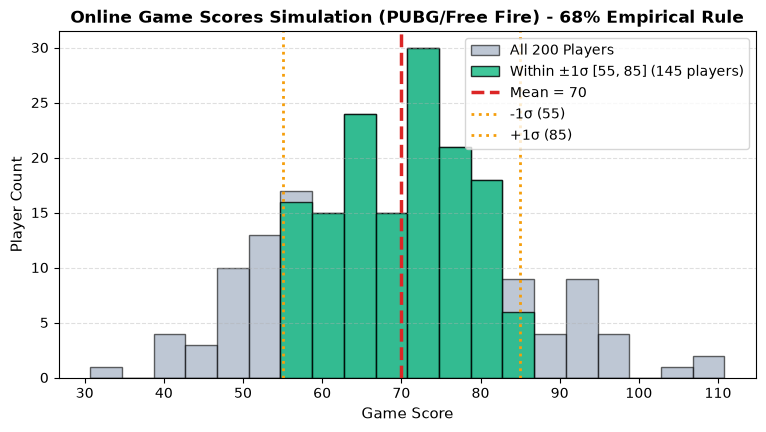

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Simulate scores of 200 online game players (Mean=70, Std=15)
np.random.seed(42)
player_scores = np.random.normal(loc=70, scale=15, size=200)

# Count players scoring within one standard deviation [55, 85]
lower_bound = 70 - 15  # 55
upper_bound = 70 + 15  # 85

within_1sd = np.sum((player_scores >= lower_bound) & (player_scores <= upper_bound))
within_1sd_pct = (within_1sd / len(player_scores)) * 100
theoretical_expected = len(player_scores) * 0.6827

print(f"Total Players Simulated         : {len(player_scores)}")
print(f"Score Parameters                : Mean = 70, Std Dev = 15")
print(f"1-Standard Deviation Range      : [{lower_bound}, {upper_bound}]")
print("-" * 65)
print(f"Observed Players within [55, 85]: {within_1sd} players ({within_1sd_pct:.1f}%)")
print(f"Theoretical 68-95-99 Rule Target: {theoretical_expected:.1f} players (~68.3%)")
print("-" * 65)
print(f"The empirical rule closely predicts our simulation within expected sampling fluctuation.")

# Visualizing the ±1σ range
plt.figure(figsize=(9, 4.5))
_, bins, _ = plt.hist(player_scores, bins=20, color='#94a3b8', edgecolor='black', alpha=0.5, label='All 200 Players')
plt.hist([s for s in player_scores if lower_bound <= s <= upper_bound], bins=bins, color='#10b981', edgecolor='black', alpha=0.8, label=f'Within ±1σ ({within_1sd} players / {within_1sd_pct:.1f}%)')

plt.axvline(70, color='#dc2626', linestyle='--', linewidth=2.5, label='Mean = 70')
plt.axvline(lower_bound, color='#f59e0b', linestyle=':', linewidth=2, label='-1σ (55)')
plt.axvline(upper_bound, color='#f59e0b', linestyle=':', linewidth=2, label='+1σ (85)')
plt.title("Online Game Scores Simulation (PUBG/Free Fire) - 68% Empirical Rule", fontsize=12, fontweight="bold")
plt.xlabel("Game Score", fontsize=11)
plt.ylabel("Player Count", fontsize=11)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.show()

## Task 4: Real-World Scenario Fitting Normal Distribution
> **Problem Statement:** Pick any real-world scenario (like delivery times for Zomato orders or playlist song durations on Spotify) and explain in 3-4 lines why the normal distribution might be a good fit for modeling this data.

### Selected Scenario: **Spotify Playlist Track Durations**

#### Explanation (3–4 Lines):
1. **Natural Commercial Clustering:** Commercial tracks strongly cluster around an industry benchmark of **~3.0 to 3.5 minutes (180–210 seconds)** due to streaming payout thresholds, radio standards, and listener attention spans, creating a single dominant central peak.
2. **Central Limit Theorem Action:** A song's final duration is the aggregate sum of numerous independent creative decisions (verse lengths, intro duration, chorus repetitions, instrumental solos); by the Central Limit Theorem, the sum of multiple independent random variables tends toward a Gaussian bell curve.
3. **Symmetric Variation:** Moderate variations occur symmetrically (2.5-minute fast pop singles vs. 4.5-minute extended ballads), with extreme outliers (30-second transition skits or 12-minute progressive epics) being exceedingly rare and tapering off equally on both ends.
4. **Modeling Fit:** Consequently, the symmetric, bell-shaped Gaussian distribution $N(\mu \approx 200\text{s}, \sigma \approx 30\text{s})$ serves as an exceptional statistical model for Spotify track lengths.